# Emotion Classifier

## Uploading Kaggle API Token

In [2]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


## Configuring API and downloading dataset

In [11]:
# Delete the old folder just to be safe
!rm -rf /content/data

!kaggle datasets download -d pankaj4321/fer-2013-facial-expression-dataset

# Unzip it
!unzip -q fer-2013-facial-expression-dataset.zip -d /content/data

print("Dataset downloaded and unzipped successfully!")

Dataset URL: https://www.kaggle.com/datasets/pankaj4321/fer-2013-facial-expression-dataset
License(s): CC-BY-NC-SA-4.0
100% 65.1M/65.1M [00:00<00:00, 91.4MB/s]

New Pre-Split Dataset downloaded and unzipped successfully!


## Imports and hardware setup

## Data Loader

In [12]:
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Defining transformations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    # The Random Erasing tweak to boost accuracy
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1), ratio=(0.3, 3.3), value=0)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load dataset
train_dataset = datasets.ImageFolder(root='/content/data/train', transform=train_transforms)
val_dataset   = datasets.ImageFolder(root='/content/data/val', transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(root='/content/data/test', transform=val_test_transforms)

# Creating dataloaders
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Test images: {len(test_dataset)}")

Training images: 28709
Validation images: 3589
Test images: 3589


## Loading model architecture

In [13]:
import torch.nn as nn
from torchvision import models

# Loading pre-trained ResNet34 using standard imagenet weights
model = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

# Freezing all layers to prevent weights from changing during training
for param in model.parameters():
    param.requires_grad = False

# Unfreezing layer 3 and 4
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True

# Modify the final fully connected classification layer (the "head")
# Get the number of input features to the final layer
num_ftrs = model.fc.in_features

# Replace it with a new layer that outputs 7 classes (for 7 emotions)
model.fc = nn.Linear(num_ftrs, 7)

# Move the entire model to GPU
model = model.to(device)

print("ResNet-34 loaded and modified successfully!")
print(f"Final layer output classes: {model.fc.out_features}")

ResNet-34 loaded and modified successfully!
Final layer output classes: 7


## Optimiser, focal loss

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# 1. Define the Custom Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

# Initialize the Loss function
criterion = FocalLoss(gamma=2.0)

# Initialize the Optimizer
# Only passing in the unfrozen layers (param=True)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

# Initialize the Learning Rate Scheduler
# Patience set to 5 for longer 30 epoch run
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=5, factor=0.5)

print("Training parameters set up successfully!")

Training parameters set up successfully!


## Training Section

In [16]:
import time
import copy
import torch

num_epochs = 30
best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

print("Starting Training...")

for epoch in range(num_epochs):
    start_time = time.time()

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_acc = 100 * correct / total

    # --- VALIDATION PHASE (Using val_loader!) ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        # UPDATE: Now correctly using val_loader
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    # Check if this is the best model so far
    if epoch_val_acc > best_acc:
        best_acc = epoch_val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), 'best_fer_resnet34.pth')

    # Step the learning rate scheduler based on validation accuracy
    scheduler.step(epoch_val_acc)

    time_elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{num_epochs}] | Time: {time_elapsed:.0f}s | "
          f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} Val Acc: {epoch_val_acc:.2f}%")

print(f"\nTraining Complete! Best Validation Accuracy: {best_acc:.2f}%")


# ==========================================
# --- FINAL TESTING PHASE (The Final Exam) ---
# ==========================================
print("\n--- Running Final Evaluation on Unseen Test Set ---")

# 1. Load the absolute best weights we saved during validation
model.load_state_dict(torch.load('best_fer_resnet34.pth'))
model.eval()

test_correct = 0
test_total = 0

with torch.no_grad():
    # 2. Run it against the completely unseen test_loader
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

final_test_acc = 100 * test_correct / test_total
print(f"🔥 OFFICIAL FINAL TEST ACCURACY: {final_test_acc:.2f}% 🔥")

Starting Training...
Epoch [1/30] | Time: 128s | Train Loss: 0.6320 Acc: 59.25% | Val Loss: 0.6164 Val Acc: 60.18%
Epoch [2/30] | Time: 130s | Train Loss: 0.5750 Acc: 62.03% | Val Loss: 0.5957 Val Acc: 60.80%
Epoch [3/30] | Time: 129s | Train Loss: 0.5376 Acc: 63.68% | Val Loss: 0.5871 Val Acc: 58.51%
Epoch [4/30] | Time: 136s | Train Loss: 0.5106 Acc: 64.99% | Val Loss: 0.6038 Val Acc: 57.90%
Epoch [5/30] | Time: 141s | Train Loss: 0.4820 Acc: 66.41% | Val Loss: 0.5597 Val Acc: 64.89%
Epoch [6/30] | Time: 136s | Train Loss: 0.4583 Acc: 67.77% | Val Loss: 0.5333 Val Acc: 65.12%
Epoch [7/30] | Time: 130s | Train Loss: 0.4367 Acc: 68.39% | Val Loss: 0.5396 Val Acc: 64.20%
Epoch [8/30] | Time: 126s | Train Loss: 0.4143 Acc: 69.69% | Val Loss: 0.5911 Val Acc: 63.44%
Epoch [9/30] | Time: 141s | Train Loss: 0.3917 Acc: 70.80% | Val Loss: 0.5214 Val Acc: 66.87%
Epoch [10/30] | Time: 132s | Train Loss: 0.3684 Acc: 71.95% | Val Loss: 0.5568 Val Acc: 65.37%
Epoch [11/30] | Time: 126s | Train Los

## Confusion Matrix

Generating predictions for the Confusion Matrix...


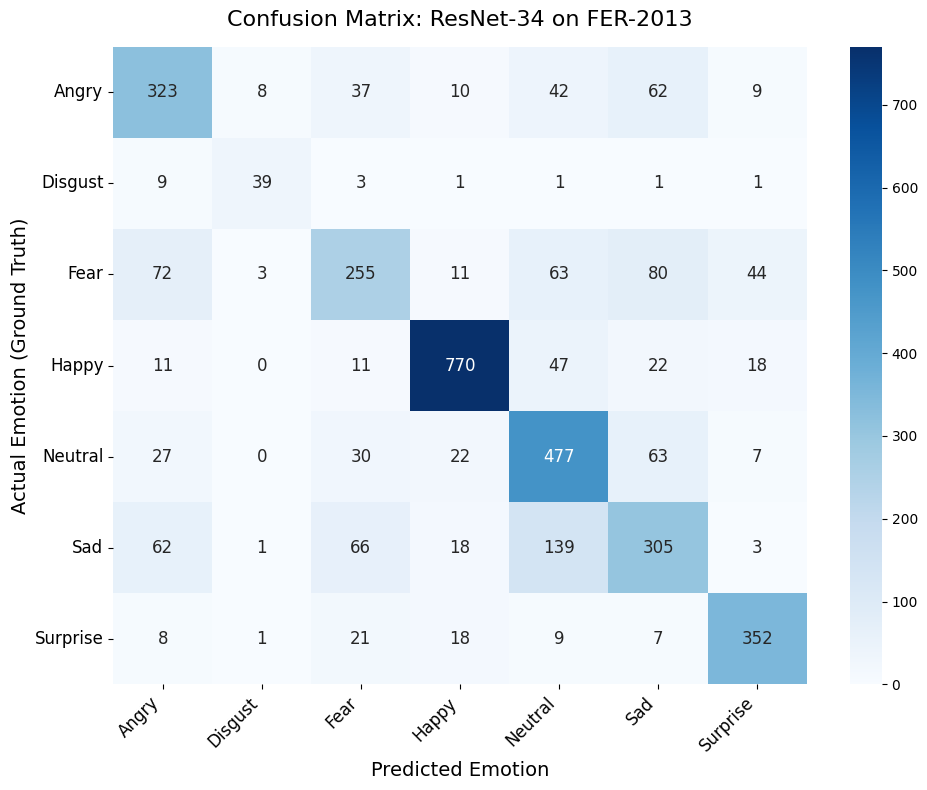

High-resolution Confusion Matrix saved as 'FER_Confusion_Matrix.png'!


In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Prepare to collect predictions
all_preds = []
all_labels = []

# Make sure we load the absolute best weights before testing
model.load_state_dict(torch.load('best_fer_resnet34.pth'))
model.eval()

print("Generating predictions for the Confusion Matrix...")

# Run the Test Set through the model
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Move data back to CPU for plotting
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Academic-Grade Plotting
plt.figure(figsize=(10, 8))
# Get class names directly from the dataset
class_names = test_dataset.classes

# Create a beautiful heatmap using Seaborn
# 'Blues' colormap is standard for research papers, 'fmt="d"' formats numbers as integers
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 12}) # Makes the numbers inside the boxes readable

# Add formatting and labels
plt.title('Confusion Matrix: ResNet-34 on FER-2013', fontsize=16, pad=15)
plt.ylabel('Actual Emotion', fontsize=14)
plt.xlabel('Predicted Emotion', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.tight_layout()

# Save a High-Resolution Image
plt.savefig('FER_Confusion_Matrix.png', dpi=300, bbox_inches='tight')

# Display it in Colab
plt.show()

print("High-resolution Confusion Matrix saved as 'FER_Confusion_Matrix.png'!")